# 実験2 (ex002): 2次元潜在空間 ($K=2$) と完全共分散ガウス分布による Deep VIB の挙動および潜在空間可視化

本ノートブックでは，Alemi et al. (ICLR 2017) "Deep Variational Information Bottleneck" の **Section 4.1.2 (Two Dimensional Embedding, Figure 1(b), Figure 2)** の再現実験を行う．

## 実験内容
1. **完全共分散ガウス分布 ($K=2$) のコレスキー分解パラメータ化**:
   - エンコーダ最終層から $2 + 4 = 6$ 次元を出力し，最初の2次元を平均 $\mu(x) \in \mathbb{R}^2$，残りの4次元から下三角コレスキー因子 $L(x) \in \mathbb{R}^{2\times 2}$（対角成分は $\mathrm{softplus}(\cdot - 5.0)$，厳密下三角成分は $10^{-2}$ スケーリング）を構成し，共分散行列 $\Sigma(x) = L(x) L(x)^\top$ を表現する．
2. **$\beta$ スイープによる誤分類率・情報量曲線の評価 (Figure 1(b) の再現)**:
   - $\beta \in \{10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}, 3\times 10^{-1}, 10^0\}$ にわたって 200 エポック学習し，狭いボトルネック ($K=2$) における 1-shot 評価と 12サンプル MC 平均評価の差，および学習・テスト間の相互情報量ギャップを検証する．
3. **2次元潜在空間の95%信頼楕円と分類器エントロピー背景図の可視化 (Figure 2 の再現)**:
   - テスト画像 1,000 枚の事後分布 $p(z|x) = \mathcal{N}(\mu(x), \Sigma(x))$ の 95% 信頼領域を楕円としてクラス別に色分け描画し，背景に変分分類器 $q(y|z)$ のシャノンエントロピー $H(q(Y|z))$ をグレースケールで重ね合わせる．

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import DeepVIB2DFullCov
from utils import (
    set_seed,
    load_mnist_gpu,
    train_vib_2d_model,
    evaluate_vib_2d,
    plot_2d_gaussian_ellipses_on_ax,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("../report/img", exist_ok=True)

train_x, train_y, test_x, test_y = load_mnist_gpu("../datasets", device=device)

Using device: cuda (NVIDIA GeForce RTX 4080)


## 1. 2次元 Deep VIB ($K=2$) の $\beta$ スイープ学習 (200 Epochs)

In [2]:
beta_list_2d = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 3e-1, 1.0]
trained_models_2d = {}
histories_2d = {}
results_2d = []

for beta in beta_list_2d:
    set_seed(42)
    model_2d = DeepVIB2DFullCov().to(device)
    ema_model_2d, hist = train_vib_2d_model(
        model_2d,
        train_x,
        train_y,
        test_x,
        test_y,
        beta=beta,
        epochs=200,
        record_every=25,
        desc=f"2D VIB (beta={beta:.0e})"
    )
    trained_models_2d[beta] = ema_model_2d
    histories_2d[beta] = hist
    torch.save(ema_model_2d.state_dict(), f"checkpoints/vib2d_beta_{beta:.0e}.pt")

    last = hist[-1]
    results_2d.append({
        "beta": beta,
        "train_err_1shot": last["train_err_1shot"],
        "train_err_mc": last["train_err_mc"],
        "test_err_1shot": last["test_err_1shot"],
        "test_err_mc": last["test_err_mc"],
        "train_izx": last["train_izx"],
        "train_izy": last["train_izy"],
        "test_izx": last["test_izx"],
        "test_izy": last["test_izy"],
    })
    print(
        f"[2D VIB beta={beta:.0e}] Test err_mc={last['test_err_mc']*100:.2f}%, "
        f"err_1={last['test_err_1shot']*100:.2f}%, I(Z,X)={last['test_izx']:.2f}b, I(Z,Y)={last['test_izy']:.3f}b"
    )

df_2d = pd.DataFrame(results_2d)
df_2d.to_csv("checkpoints/ex002_results.csv", index=False)
df_2d

[2D VIB beta=1e-05] Test err_mc=3.32%, err_1=3.31%, I(Z,X)=838.14b, I(Z,Y)=2.957b
[2D VIB beta=1e-04] Test err_mc=3.24%, err_1=3.25%, I(Z,X)=244.24b, I(Z,Y)=2.978b
[2D VIB beta=1e-03] Test err_mc=3.47%, err_1=3.38%, I(Z,X)=60.66b, I(Z,Y)=3.010b
[2D VIB beta=1e-02] Test err_mc=3.25%, err_1=3.51%, I(Z,X)=14.34b, I(Z,Y)=3.035b
[2D VIB beta=1e-01] Test err_mc=3.34%, err_1=4.86%, I(Z,X)=5.60b, I(Z,Y)=2.788b
[2D VIB beta=3e-01] Test err_mc=3.69%, err_1=20.62%, I(Z,X)=3.07b, I(Z,Y)=2.310b
[2D VIB beta=1e+00] Test err_mc=73.09%, err_1=85.04%, I(Z,X)=0.07b, I(Z,Y)=0.133b


2D VIB (beta=1e+00): 100%|##########| 200/200 [00:37<00:00,  5.28it/s, test_mc=73.09%, I(Z,X)=0.1b]


,beta,train_err_1shot,train_err_mc,test_err_1shot,test_err_mc,train_izx,train_izy,test_izx,test_izy
0,0.00001,0.000000,0.000000,0.0331,0.0332,870.406067,3.319345,838.135200,2.956644
1,0.00010,0.000000,0.000000,0.0325,0.0324,254.534250,3.313011,244.242925,2.978254
2,0.00100,0.000000,0.000000,0.0338,0.0347,63.520683,3.286011,60.655431,3.009804
3,0.01000,0.000000,0.000000,0.0351,0.0325,14.978482,3.247038,14.342477,3.034603
4,0.10000,0.004450,0.000000,0.0486,0.0334,5.800029,2.942991,5.596030,2.788208
5,0.30000,0.166683,0.003350,0.2062,0.0369,3.167771,2.412406,3.073352,2.309934
6,1.00000,0.842400,0.718467,0.8504,0.7309,0.074797,0.138519,0.071162,0.132916


## 2. Figure 1(b) および $K=2$ における Information Bottleneck 曲線の可視化

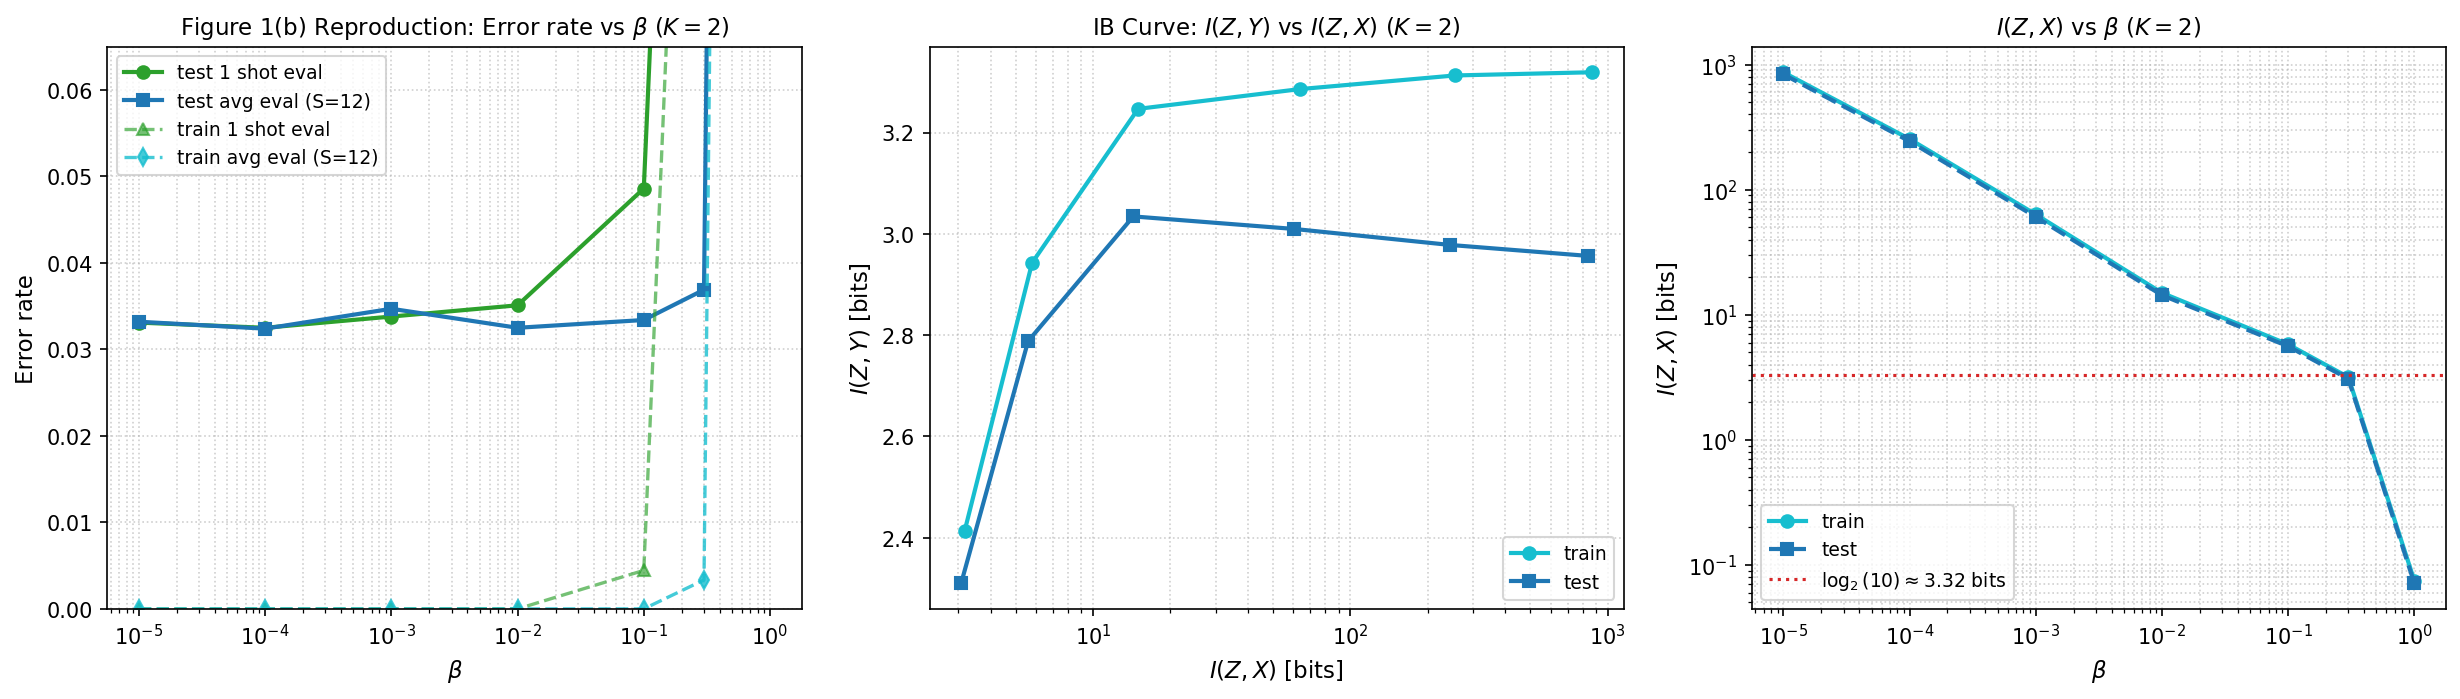

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) Figure 1(b) 再現: Error rate vs beta (K=2)
ax = axes[0]
ax.plot(df_2d["beta"], df_2d["test_err_1shot"], "o-", color="#2ca02c", lw=2, label="test 1 shot eval")
ax.plot(df_2d["beta"], df_2d["test_err_mc"], "s-", color="#1f77b4", lw=2, label="test avg eval (S=12)")
ax.plot(df_2d["beta"], df_2d["train_err_1shot"], "^--", color="#2ca02c", alpha=0.65, lw=1.6, label="train 1 shot eval")
ax.plot(df_2d["beta"], df_2d["train_err_mc"], "d--", color="#17becf", alpha=0.8, lw=1.6, label="train avg eval (S=12)")
ax.set_xscale("log")
ax.set_ylim(0.0, 0.065)
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("Error rate", fontsize=11)
ax.set_title("Figure 1(b) Reproduction: Error rate vs $\\beta$ ($K=2$)", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="upper left")

# (b) IB Curve for K=2: I(Z, Y) vs I(Z, X)
ax = axes[1]
df_ib2 = df_2d[df_2d["beta"] <= 3e-1].sort_values("train_izx")
ax.plot(df_ib2["train_izx"], df_ib2["train_izy"], "o-", color="#17becf", lw=2, label="train")
ax.plot(df_ib2["test_izx"], df_ib2["test_izy"], "s-", color="#1f77b4", lw=2, label="test")
ax.set_xscale("log")
ax.set_xlabel("$I(Z, X)$ [bits]", fontsize=11)
ax.set_ylabel("$I(Z, Y)$ [bits]", fontsize=11)
ax.set_title("IB Curve: $I(Z, Y)$ vs $I(Z, X)$ ($K=2$)", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="lower right")

# (c) I(Z, X) vs beta for K=2
ax = axes[2]
ax.plot(df_2d["beta"], df_2d["train_izx"].clip(lower=1e-4), "o-", color="#17becf", lw=2, label="train")
ax.plot(df_2d["beta"], df_2d["test_izx"].clip(lower=1e-4), "s--", color="#1f77b4", lw=2, label="test")
ax.axhline(np.log2(10.0), color="#d62728", ls=":", lw=1.5, label="$\\log_2(10) \\approx 3.32$ bits")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("$I(Z, X)$ [bits]", fontsize=11)
ax.set_title("$I(Z, X)$ vs $\\beta$ ($K=2$)", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9, loc="lower left")

plt.tight_layout()
plt.savefig("../report/img/ex002_fig1b_k2.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. 2次元ガウス事後分布 $p(z|x)$ の95%信頼楕円と分類器エントロピーの可視化 (Figure 2 の再現)

論文 Figure 2 (a) $\beta = 10^{-3}$, (b) $\beta = 10^{-1}$, (c) $\beta = 10^0$（および中間領域の比較）について，テストデータ1,000枚の95%信頼楕円と変分分類器エントロピー $H(q(Y|z))$ を描画する．

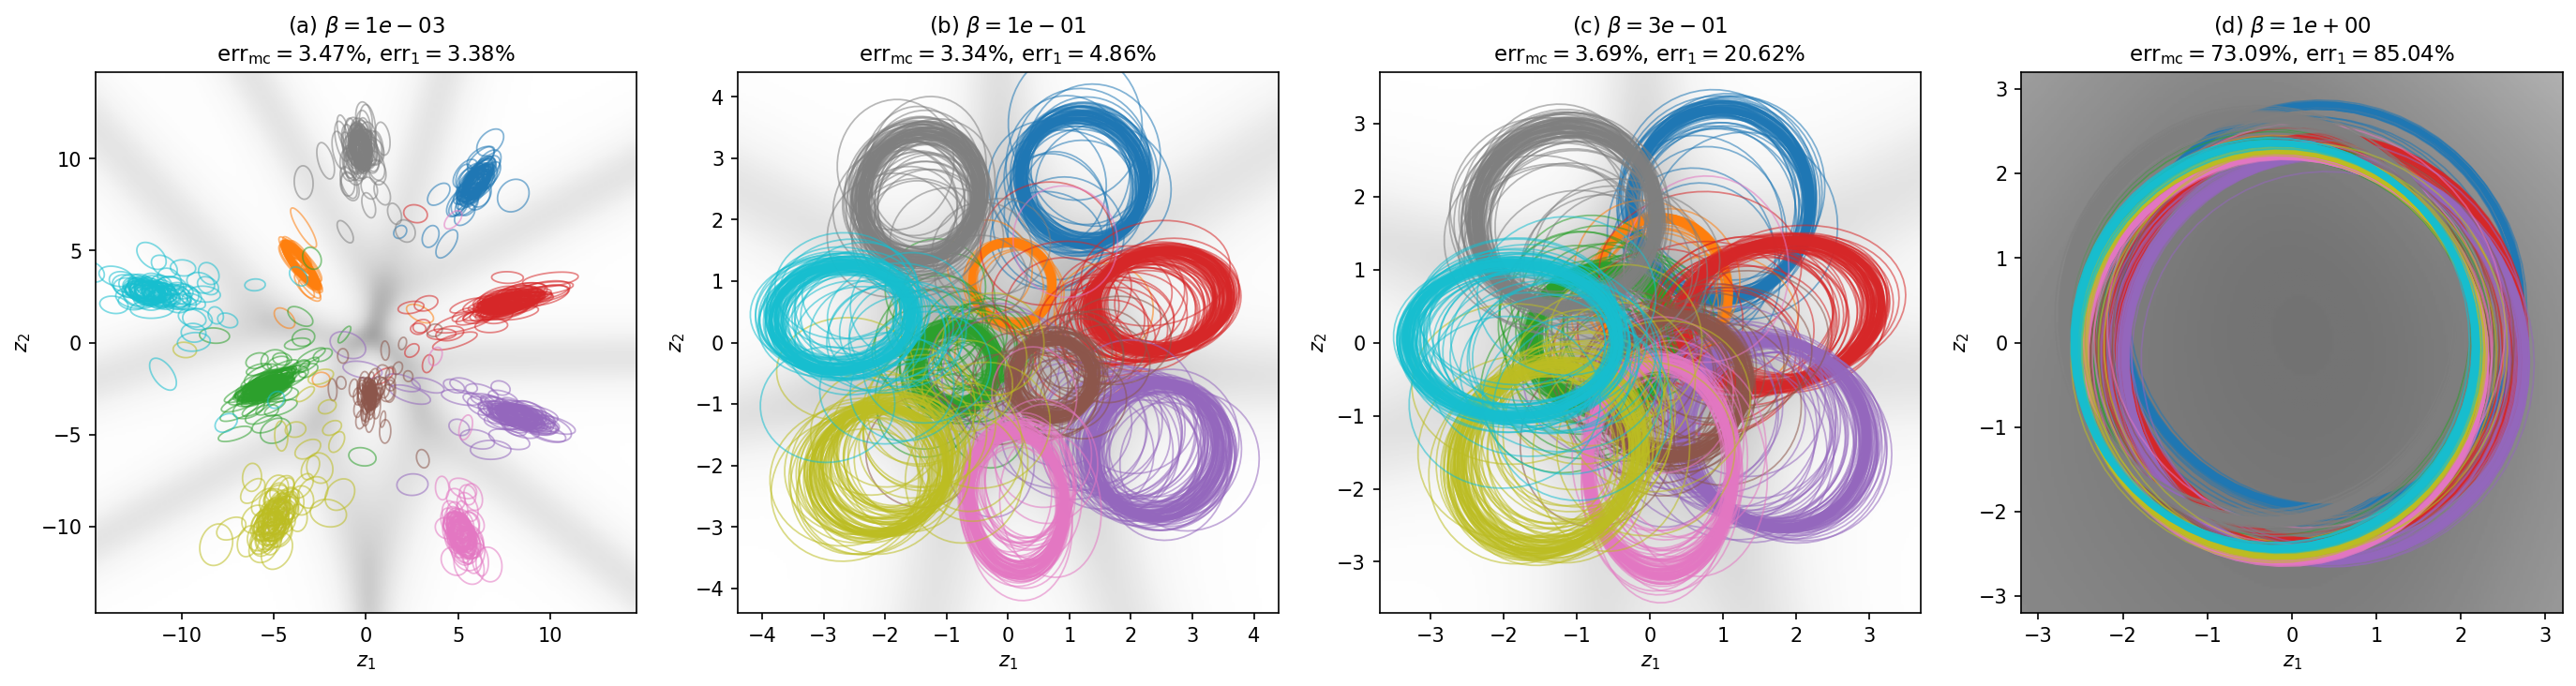

In [4]:
plot_betas = [1e-3, 1e-1, 3e-1, 1.0]
panel_labels = ["(a)", "(b)", "(c)", "(d)"]

fig, axes = plt.subplots(1, 4, figsize=(18.5, 4.6))
for ax, b_val, p_lbl in zip(axes, plot_betas, panel_labels):
    row = df_2d[df_2d["beta"] == b_val].iloc[0]
    err_mc_pct = row["test_err_mc"] * 100.0
    err_1_pct = row["test_err_1shot"] * 100.0
    title_str = (
        f"{p_lbl} $\\beta = {b_val:.0e}$\n"
        f"$\\mathrm{{err}}_{{\\mathrm{{mc}}}} = {err_mc_pct:.2f}\\%$, "
        f"$\\mathrm{{err}}_1 = {err_1_pct:.2f}\\%$"
    )
    plot_2d_gaussian_ellipses_on_ax(
        ax,
        trained_models_2d[b_val],
        test_x,
        test_y,
        num_images=1000,
        grid_res=200,
        title=title_str
    )

plt.tight_layout()
plt.savefig("../report/img/ex002_fig2_embeddings.png", dpi=180, bbox_inches="tight")
plt.show()